Daily Weather Time Series Data - Delhi, India

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

Тема: Прогнозування часових рядів на основі кліматичних даних

Мета роботи: Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

Вихідні дані

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.

Завантажити датасет з Kaggle.

Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

Ознайомитися зі структурою датасету (head(), info(), describe()).

Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

Дослідницький аналіз даних (EDA)
-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

Побудувати щонайменше три моделі прогнозування:
-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

Оцінка моделей Для кожної моделі обчислити метрики:
-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:

from google.colab import files

uploaded = files.upload()


Saving kaggel_weather_2013_to_2024.csv to kaggel_weather_2013_to_2024.csv


In [2]:

import pandas as pd

df = pd.read_csv("kaggel_weather_2013_to_2024.csv")

display(df.head())
print(df.columns.tolist())


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

df = pd.read_csv("kaggel_weather_2013_to_2024.csv")

print("Розмір датасету:", df.shape)
print("\nПерші 5 рядків:")
display(df.head())

print("\nІнформація про датасет:")
df.info()

print("\nОписова статистика:")
display(df.describe(include="all"))

print("\nНазви стовпців:")
print(df.columns.tolist())


Розмір датасету: (3557, 29)

Перші 5 рядків:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622



Назви стовпців:
['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


In [4]:

df.columns = df.columns.str.strip()

# Пошук колонки дати
date_candidates = [
    c for c in df.columns
    if c.lower() in ["date", "datetime", "time", "дата"]
]

if not date_candidates:
    raise ValueError(
        f"Не знайдено дату. Назви колонок: {df.columns.tolist()}"
    )

date_col = date_candidates[0]
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df = df.dropna(subset=[date_col]).sort_values(date_col)

# Пошук колонки температури
temp_candidates = [
    c for c in df.columns
    if any(x in c.lower() for x in
           ["temperature", "temp", "meantemp", "температур"])
]

if not temp_candidates:
    raise ValueError(
        "Не знайдено температуру. Перевір назви колонок у кроці 1."
    )

preferred = [
    c for c in temp_candidates
    if "mean" in c.lower() or "серед" in c.lower()
]
target_col = preferred[0] if preferred else temp_candidates[0]

print("Колонка дати:", date_col)
print("Колонка температури:", target_col)

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.set_index(date_col).sort_index()
df = df[~df.index.duplicated(keep="first")]

# Формуємо часовий ряд
weather = df[[target_col]].copy()
weather.columns = ["Temperature"]

weather["Temperature"] = weather["Temperature"].interpolate(
    method="time"
).ffill().bfill()

weather = weather.dropna()

print("\nРозмір часового ряду:", weather.shape)
print("Період:", weather.index.min(), "-", weather.index.max())
print("\nПропущені значення:")
print(weather.isna().sum())

display(weather.head())


Колонка дати: DATE
Колонка температури: tempmax

Розмір часового ряду: (3556, 1)
Період: 2013-04-14 00:00:00 - 2024-11-30 00:00:00

Пропущені значення:
Temperature    0
dtype: int64


,Temperature
DATE,
2013-04-14,37.7
2013-04-15,37.5
2013-04-16,40.1
2013-04-17,36.4
2013-04-18,37.5


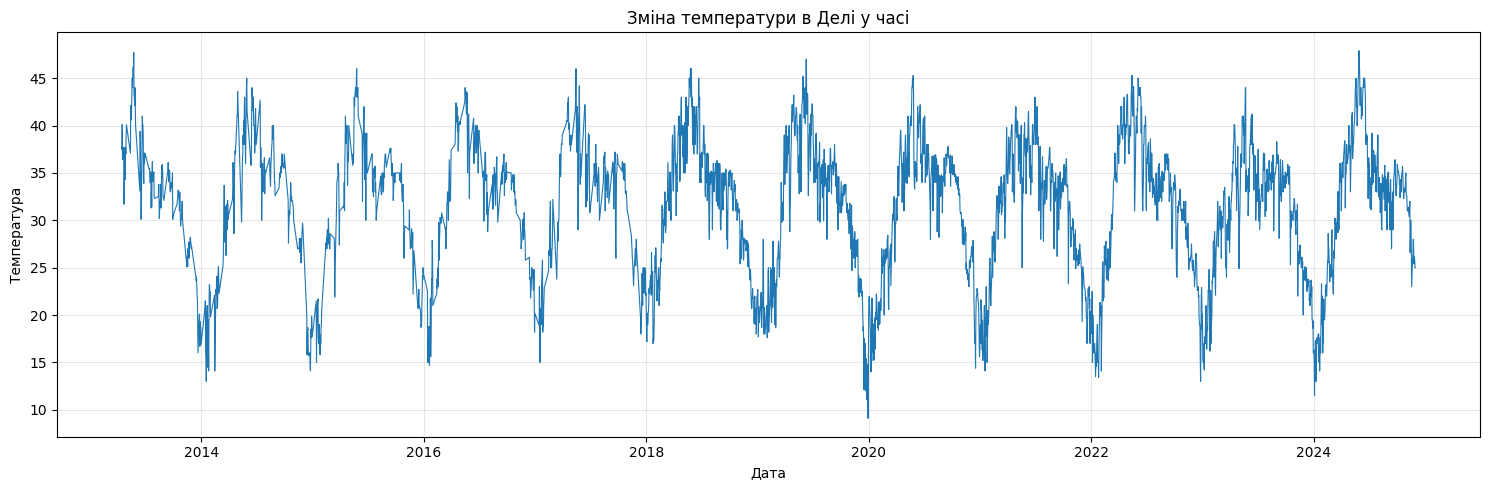

In [5]:

plt.figure(figsize=(15, 5))
plt.plot(weather.index, weather["Temperature"], linewidth=0.8)
plt.title("Зміна температури в Делі у часі")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


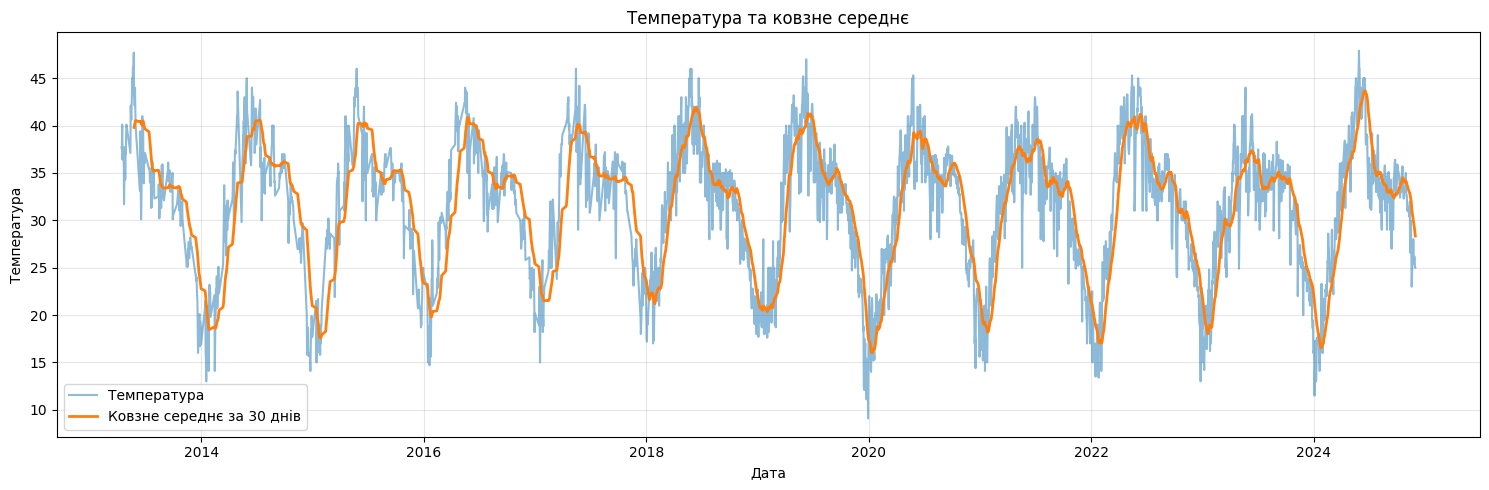

In [6]:

weather["Rolling_Mean_30"] = (
    weather["Temperature"].rolling(30).mean()
)

plt.figure(figsize=(15, 5))
plt.plot(
    weather.index, weather["Temperature"],
    label="Температура", alpha=0.5
)
plt.plot(
    weather.index, weather["Rolling_Mean_30"],
    label="Ковзне середнє за 30 днів", linewidth=2
)
plt.title("Температура та ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


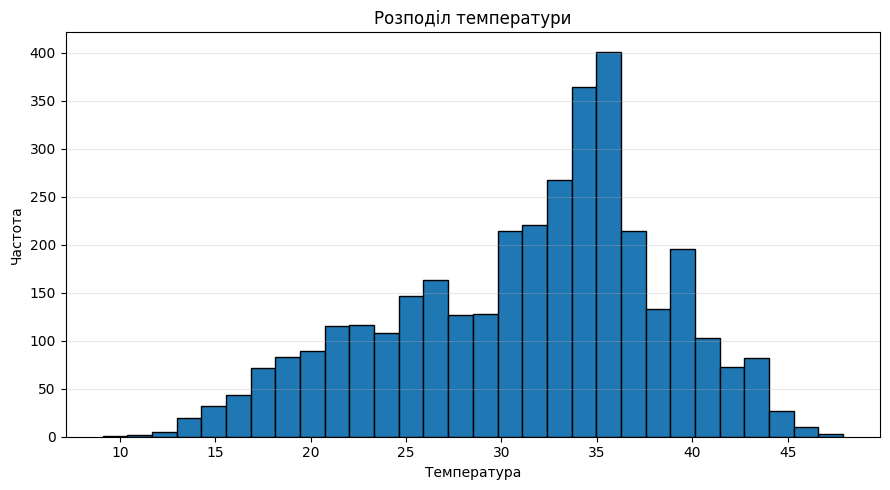

In [7]:

plt.figure(figsize=(9, 5))
plt.hist(weather["Temperature"], bins=30, edgecolor="black")
plt.title("Розподіл температури")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


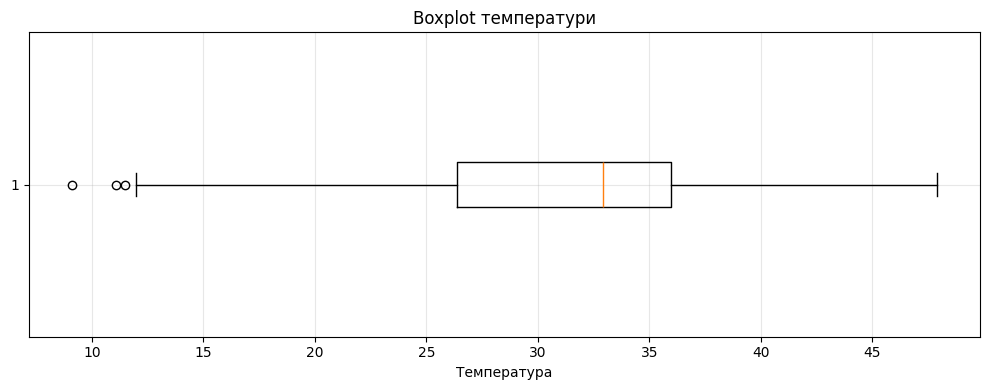

In [8]:

plt.figure(figsize=(10, 4))
plt.boxplot(weather["Temperature"], vert=False)
plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


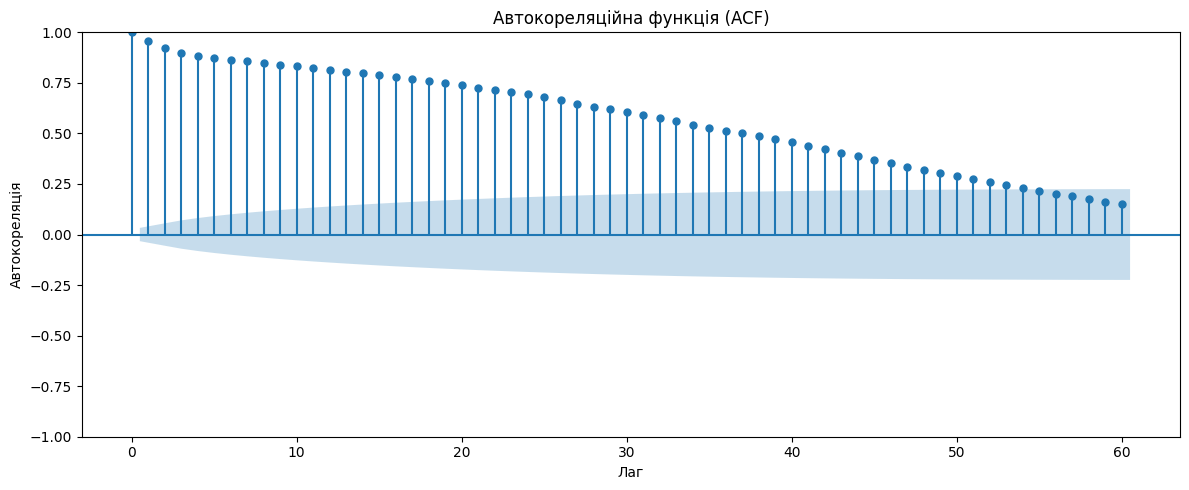

In [9]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

temperature = weather["Temperature"].astype(float)

acf_lags = min(60, len(temperature) // 2 - 1)

fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(temperature, lags=acf_lags, ax=ax)
ax.set_title("Автокореляційна функція (ACF)")
ax.set_xlabel("Лаг")
ax.set_ylabel("Автокореляція")
plt.tight_layout()
plt.show()


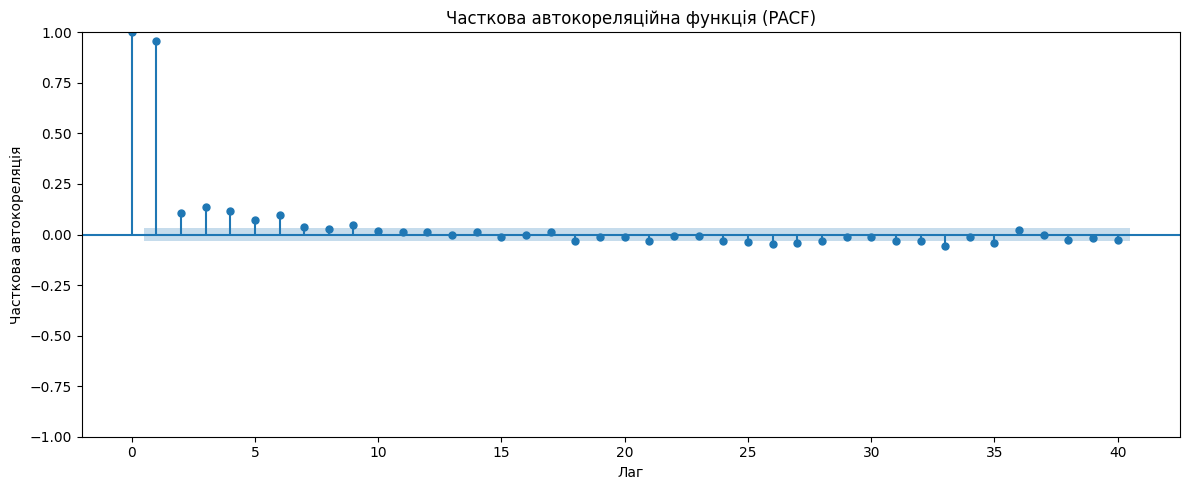

In [10]:

pacf_lags = min(40, len(temperature) // 2 - 1)

fig, ax = plt.subplots(figsize=(12, 5))
plot_pacf(temperature, lags=pacf_lags, ax=ax, method="ywm")
ax.set_title("Часткова автокореляційна функція (PACF)")
ax.set_xlabel("Лаг")
ax.set_ylabel("Часткова автокореляція")
plt.tight_layout()
plt.show()


Train: 2844
Test: 712
Початок тесту: 2022-12-20 00:00:00
Кінець тесту: 2024-11-30 00:00:00


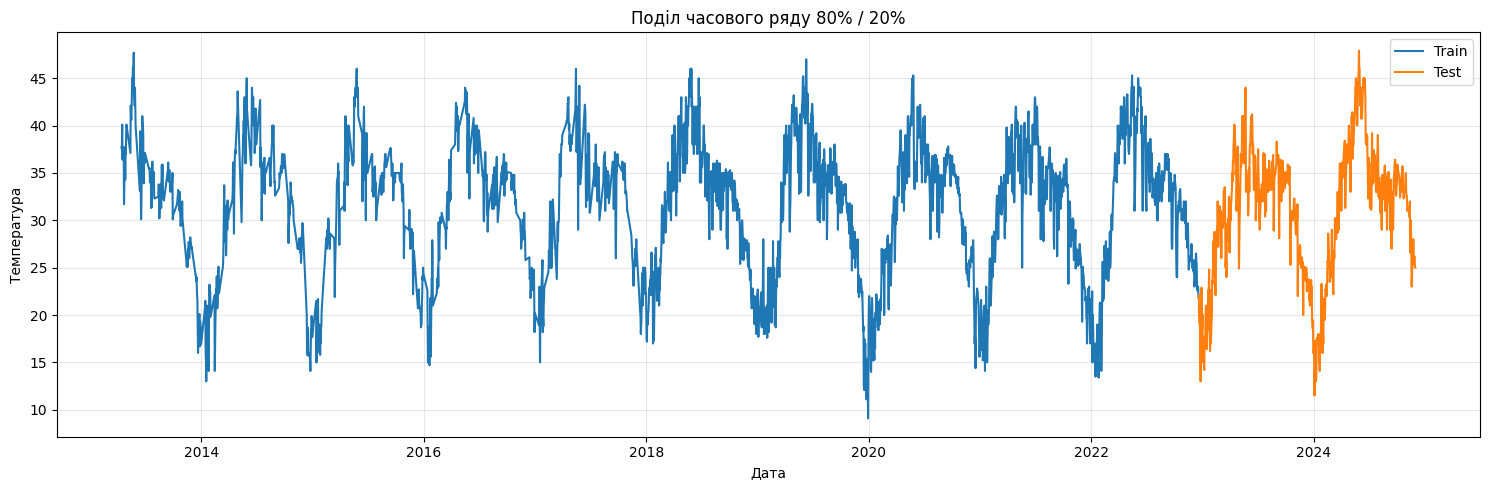

In [11]:

temperature = weather["Temperature"].dropna().astype(float)

split_idx = int(len(temperature) * 0.8)

train = temperature.iloc[:split_idx]
test = temperature.iloc[split_idx:]

print("Train:", len(train))
print("Test:", len(test))
print("Початок тесту:", test.index.min())
print("Кінець тесту:", test.index.max())

plt.figure(figsize=(15, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.title("Поділ часового ряду 80% / 20%")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

%pip -q install statsmodels


In [16]:


from statsmodels.tsa.arima.model import ARIMA

# Перетворюємо дані на числові значення без індексу
train_values = train.to_numpy(dtype=float)

# Навчаємо модель ARIMA
arima_model = ARIMA(
    train_values,
    order=(5, 1, 0)
)

arima_fit = arima_model.fit()

print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2844
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -6109.741
Date:                Fri, 23 Oct 2026   AIC                          12231.482
Time:                        16:07:24   BIC                          12267.197
Sample:                             0   HQIC                         12244.364
                               - 2844                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1819      0.015    -11.893      0.000      -0.212      -0.152
ar.L2         -0.2015      0.018    -11.131      0.000      -0.237      -0.166
ar.L3         -0.1589      0.019     -8.184      0.0

In [17]:

# Прогноз ARIMA на тестовий період
arima_values = arima_fit.forecast(steps=len(test))

# Прив'язуємо прогноз до дат тестової вибірки
arima_forecast = pd.Series(
    np.asarray(arima_values),
    index=test.index,
    name="ARIMA"
)

print("Прогноз успішно побудовано!")
display(arima_forecast.head())



Прогноз успішно побудовано!


,ARIMA
DATE,
2022-12-20,22.125385
2022-12-21,22.262823
2022-12-22,22.327750
2022-12-23,22.371180
2022-12-24,22.412602


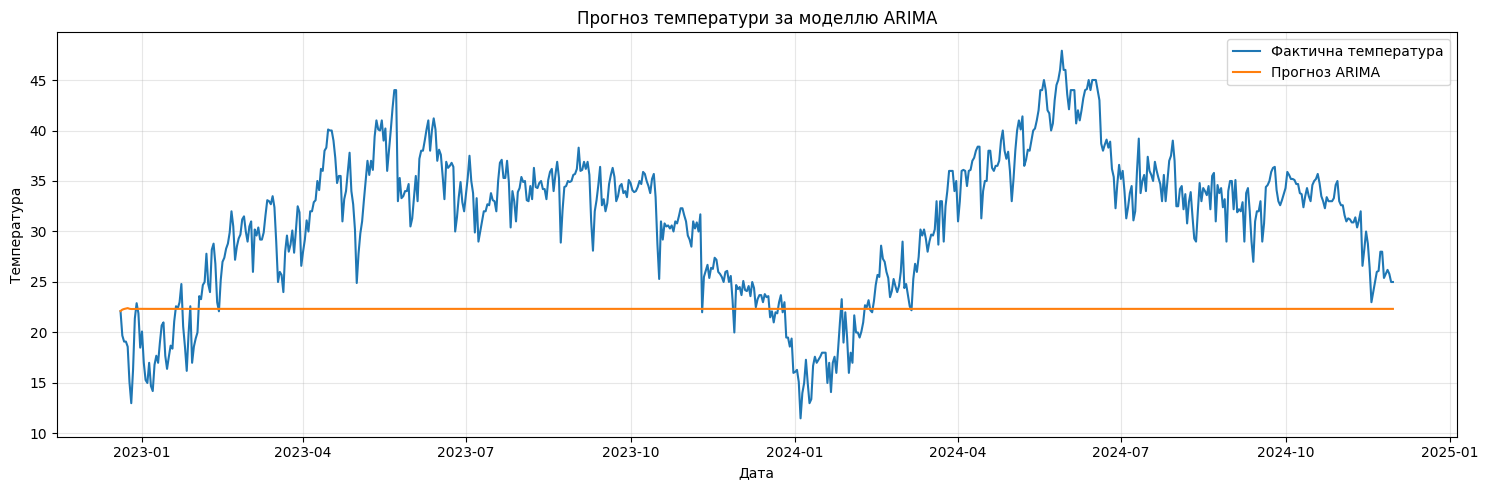

In [18]:

plt.figure(figsize=(15, 5))

plt.plot(test.index, test.values, label="Фактична температура")
plt.plot(arima_forecast.index, arima_forecast.values, label="Прогноз ARIMA")

plt.title("Прогноз температури за моделлю ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


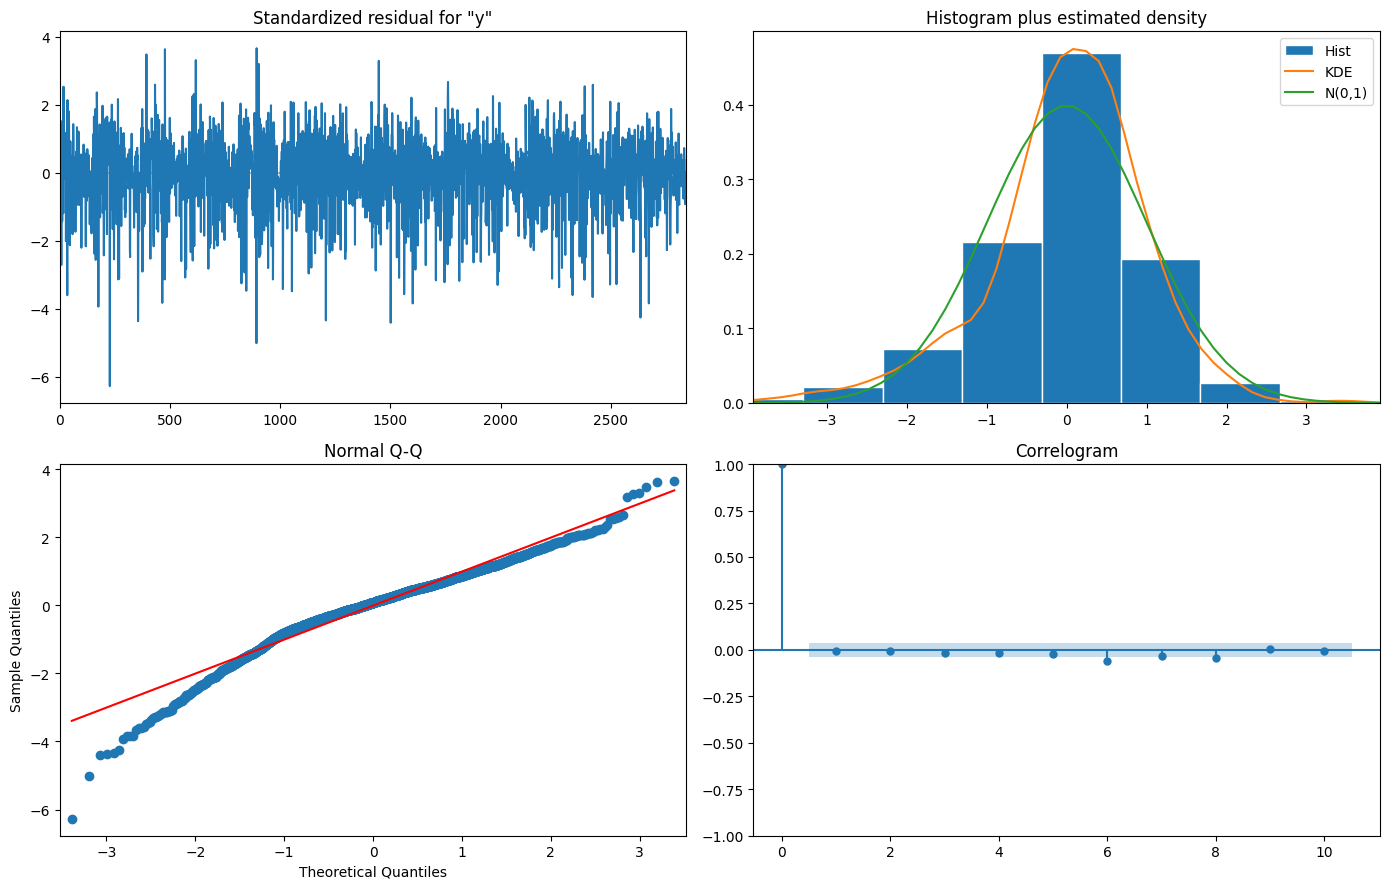

In [19]:

arima_fit.plot_diagnostics(figsize=(14, 9))
plt.tight_layout()
plt.show()


In [20]:

%pip -q install prophet


In [21]:

from prophet import Prophet

prophet_train = pd.DataFrame({
    "ds": pd.to_datetime(train.index),
    "y": train.values
})

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Модель Prophet успішно навчена.")


Модель Prophet успішно навчена.


In [22]:

future = pd.DataFrame({
    "ds": pd.to_datetime(test.index)
})

prophet_result = prophet_model.predict(future)

prophet_forecast = pd.Series(
    prophet_result["yhat"].to_numpy(),
    index=test.index,
    name="Prophet"
)

display(
    prophet_result[
        ["ds", "yhat", "yhat_lower", "yhat_upper"]
    ].head()
)


,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,20.228217,17.005745,23.709644
1,2022-12-21,20.050095,16.589527,23.786016
2,2022-12-22,19.895474,16.483748,23.436696
3,2022-12-23,19.763949,16.451330,23.216457
4,2022-12-24,19.654655,16.272682,22.963741


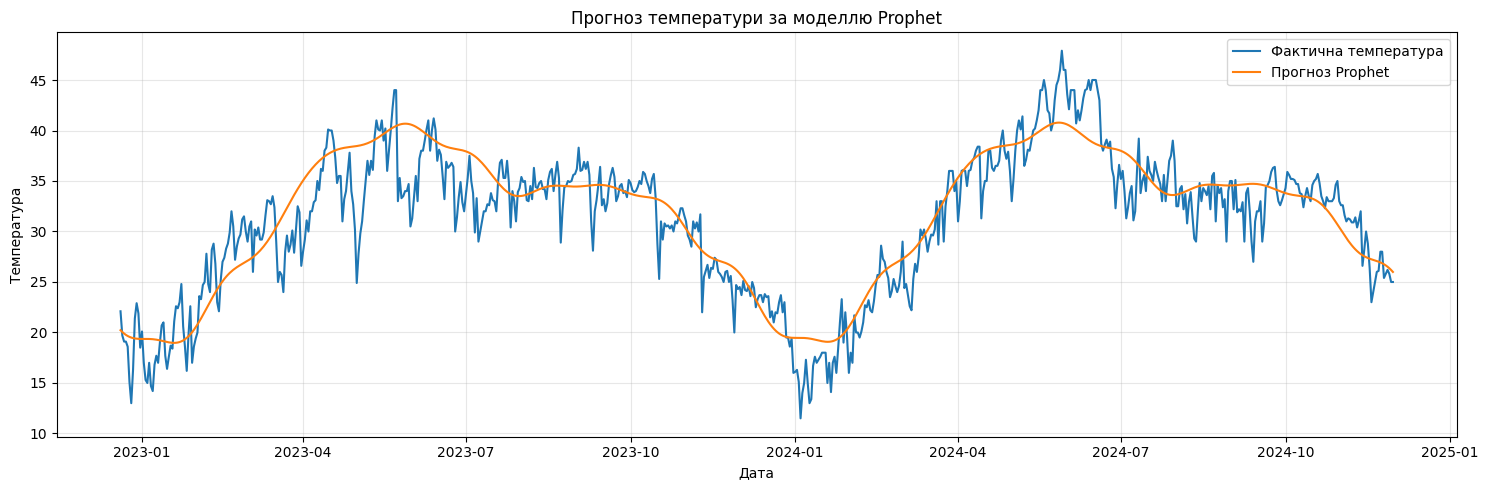

In [23]:

plt.figure(figsize=(15, 5))

plt.plot(test.index, test.values, label="Фактична температура")
plt.plot(
    prophet_forecast.index,
    prophet_forecast.values,
    label="Прогноз Prophet"
)

plt.title("Прогноз температури за моделлю Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


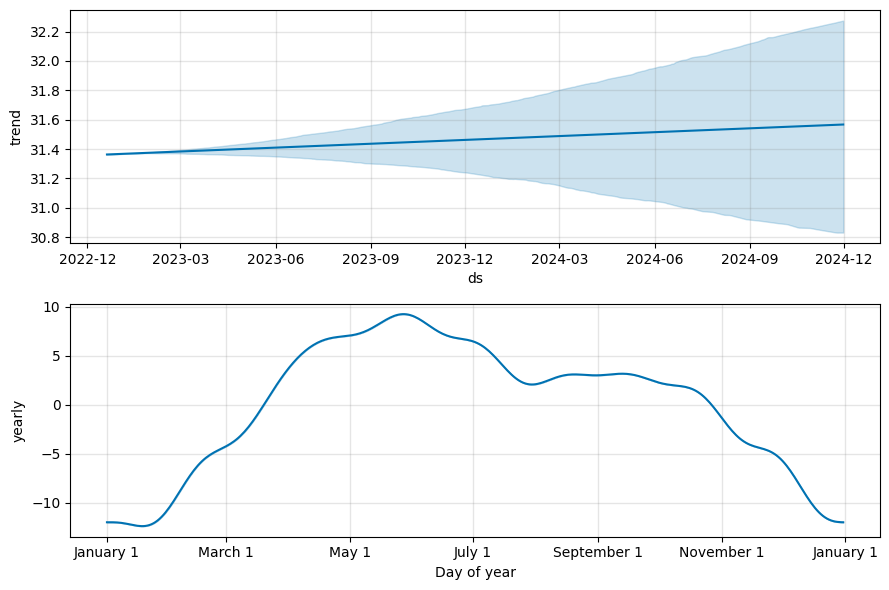

In [24]:

fig = prophet_model.plot_components(prophet_result)
plt.tight_layout()
plt.show()


In [25]:

from sklearn.preprocessing import MinMaxScaler

temperature = weather["Temperature"].dropna().astype(float)

split_idx = int(len(temperature) * 0.8)
train = temperature.iloc[:split_idx]
test = temperature.iloc[split_idx:]

values = temperature.to_numpy().reshape(-1, 1)

# Масштабування тільки за тренувальною вибіркою
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:split_idx])

scaled_values = scaler.transform(values)

# Кількість попередніх днів для прогнозування
lookback = 30

X_all = []
y_all = []
target_positions = []

for i in range(lookback, len(scaled_values)):
    X_all.append(scaled_values[i-lookback:i, 0])
    y_all.append(scaled_values[i, 0])
    target_positions.append(i)

X_all = np.array(X_all).reshape(-1, lookback, 1)
y_all = np.array(y_all)
target_positions = np.array(target_positions)

# Поділ у часовому порядку
train_mask = target_positions < split_idx
test_mask = target_positions >= split_idx

X_train_lstm = X_all[train_mask]
y_train_lstm = y_all[train_mask]

X_test_lstm = X_all[test_mask]
y_test_lstm = y_all[test_mask]

print("X_train:", X_train_lstm.shape)
print("X_test:", X_test_lstm.shape)


X_train: (2814, 30, 1)
X_test: (712, 30, 1)


In [26]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

lstm_model = Sequential([
    LSTM(64, input_shape=(lookback, 1)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0645 - val_loss: 0.0077
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0105 - val_loss: 0.0085
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - loss: 0.0083 - val_loss: 0.0081
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - loss: 0.0075 - val_loss: 0.0063
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0070 - val_loss: 0.0058
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0066 - val_loss: 0.0045
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0060 - val_loss: 0.0047
Epoch 8/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0062 - val_loss: 0.0052
Epoch 9/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0059 - val_loss: 0.0046
Epoch 10/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0053 - val_loss: 0.0040
Epoch 11/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0051 - val_loss: 0.0037
Epoch 12/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0

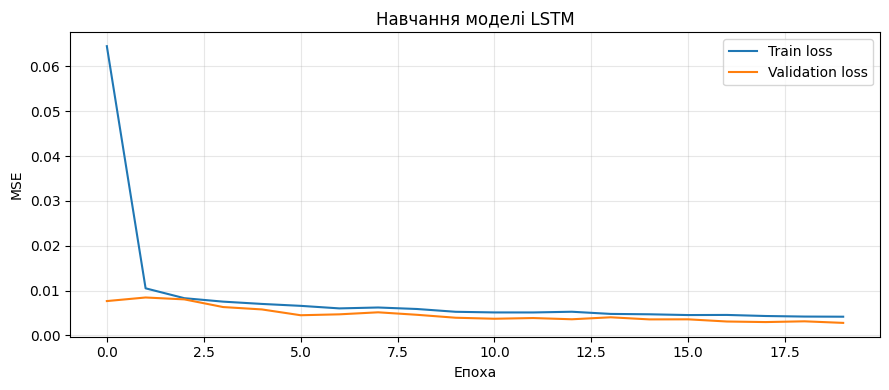

In [27]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.title("Навчання моделі LSTM")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:

lstm_scaled_forecast = lstm_model.predict(
    X_test_lstm,
    verbose=0
)

# Повернення до початкової шкали температури
lstm_values = scaler.inverse_transform(
    lstm_scaled_forecast
).ravel()

lstm_actual_values = scaler.inverse_transform(
    y_test_lstm.reshape(-1, 1)
).ravel()

lstm_dates = temperature.index[target_positions[test_mask]]

lstm_forecast = pd.Series(
    lstm_values,
    index=lstm_dates,
    name="LSTM"
)

lstm_actual = pd.Series(
    lstm_actual_values,
    index=lstm_dates,
    name="Actual"
)

display(pd.DataFrame({
    "Фактична температура": lstm_actual,
    "Прогноз LSTM": lstm_forecast
}).head())


,Фактична температура,Прогноз LSTM
DATE,,
2022-12-20,22.1,22.700951
2022-12-21,19.7,22.497490
2022-12-22,19.1,21.436420
2022-12-23,19.1,20.572908
2022-12-24,18.6,20.057549


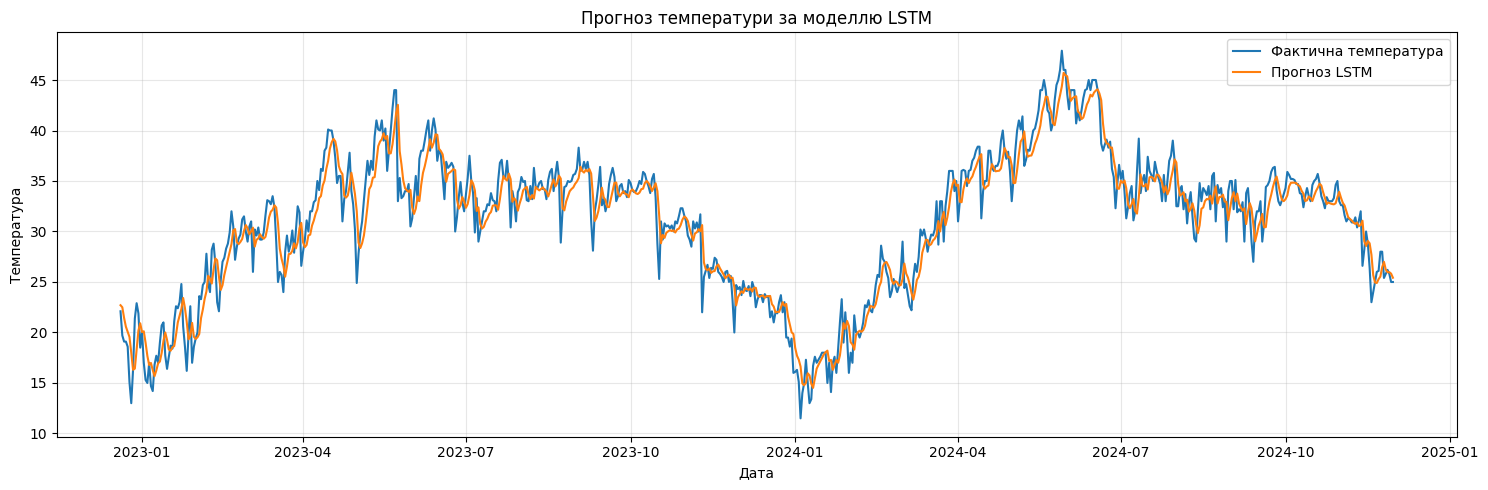

In [29]:

plt.figure(figsize=(15, 5))

plt.plot(lstm_actual.index, lstm_actual.values,
         label="Фактична температура")

plt.plot(lstm_forecast.index, lstm_forecast.values,
         label="Прогноз LSTM")

plt.title("Прогноз температури за моделлю LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # MAPE не визначена для нульових фактичних значень
    mask = np.abs(actual) > 1e-8

    if mask.any():
        mape = np.mean(
            np.abs(
                (actual[mask] - predicted[mask]) / actual[mask]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

metrics_arima = calculate_metrics(test, arima_forecast)

metrics_prophet = calculate_metrics(
    test, prophet_forecast
)

metrics_lstm = calculate_metrics(
    lstm_actual, lstm_forecast
)

print("ARIMA:", metrics_arima)
print("Prophet:", metrics_prophet)
print("LSTM:", metrics_lstm)


ARIMA: {'MAE': 9.749682240971126, 'RMSE': np.float64(11.125210873145953), 'MAPE (%)': np.float64(29.689440616920592)}
Prophet: {'MAE': 2.335363923814199, 'RMSE': np.float64(3.0271363292662183), 'MAPE (%)': np.float64(8.262669995653669)}
LSTM: {'MAE': 1.5963172875093607, 'RMSE': np.float64(2.067996671198516), 'MAPE (%)': np.float64(5.599712131846041)}


In [31]:

metrics_df = pd.DataFrame({
    "ARIMA": metrics_arima,
    "Prophet": metrics_prophet,
    "LSTM": metrics_lstm
}).T

metrics_df.index.name = "Модель"

print("Порівняння точності моделей:")
display(metrics_df.round(4))


Порівняння точності моделей:


,MAE,RMSE,MAPE (%)
Модель,,,
ARIMA,9.7497,11.1252,29.6894
Prophet,2.3354,3.0271,8.2627
LSTM,1.5963,2.0680,5.5997


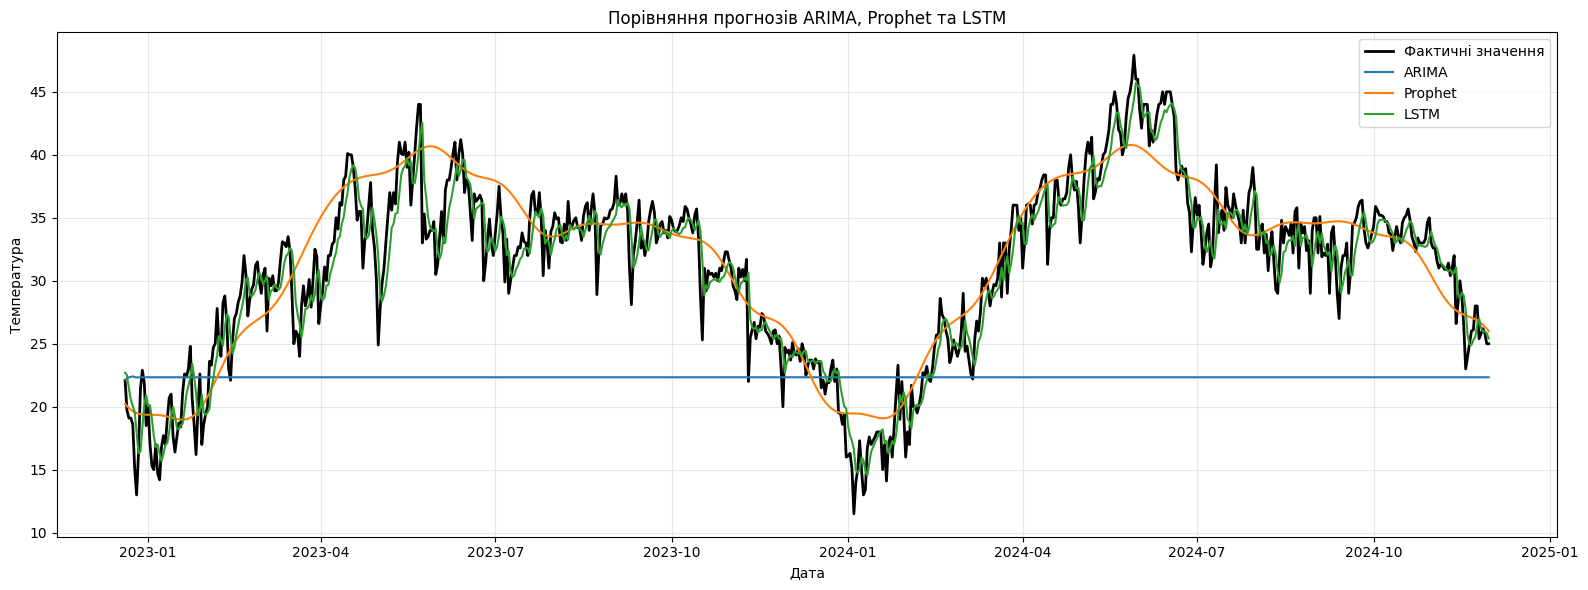

In [32]:

plt.figure(figsize=(16, 6))

plt.plot(
    test.index, test.values,
    label="Фактичні значення",
    color="black",
    linewidth=2
)

plt.plot(arima_forecast.index, arima_forecast.values,
         label="ARIMA")

plt.plot(prophet_forecast.index, prophet_forecast.values,
         label="Prophet")

plt.plot(lstm_forecast.index, lstm_forecast.values,
         label="LSTM")

plt.title("Порівняння прогнозів ARIMA, Prophet та LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


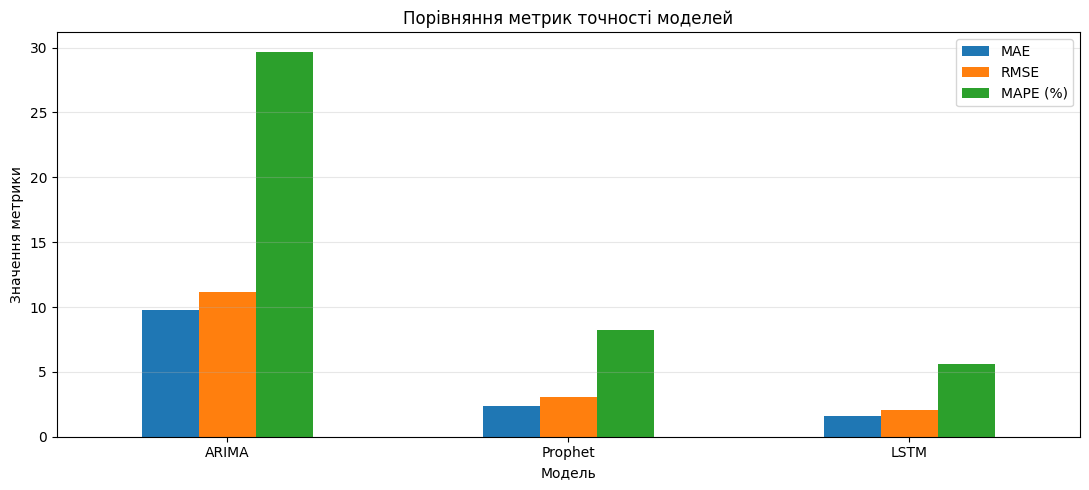

In [33]:

metrics_df[["MAE", "RMSE", "MAPE (%)"]].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Порівняння метрик точності моделей")
plt.xlabel("Модель")
plt.ylabel("Значення метрики")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:

print("Рейтинг за RMSE:")
display(metrics_df.sort_values("RMSE")[["RMSE"]].round(4))

print("Рейтинг за MAE:")
display(metrics_df.sort_values("MAE")[["MAE"]].round(4))

print("Рейтинг за MAPE:")
display(metrics_df.sort_values("MAPE (%)")[["MAPE (%)"]].round(4))

best_model = metrics_df["RMSE"].idxmin()

print("\nНайкраща модель за RMSE:", best_model)
print("Її показники:")
display(metrics_df.loc[[best_model]].round(4))


Рейтинг за RMSE:


,RMSE
Модель,
LSTM,2.0680
Prophet,3.0271
ARIMA,11.1252


Рейтинг за MAE:


,MAE
Модель,
LSTM,1.5963
Prophet,2.3354
ARIMA,9.7497


Рейтинг за MAPE:


,MAPE (%)
Модель,
LSTM,5.5997
Prophet,8.2627
ARIMA,29.6894



Найкраща модель за RMSE: LSTM
Її показники:


,MAE,RMSE,MAPE (%)
Модель,,,
LSTM,1.5963,2.068,5.5997


## Висновок

У ході лабораторної роботи було досліджено часовий ряд погодних даних міста Делі (Індія) за допомогою моделей прогнозування ARIMA, Prophet та LSTM. Було виконано попередній аналіз даних, побудовано графіки та оцінено точність прогнозування кожної моделі за метриками MAE, RMSE та MAPE.

За результатами порівняння найкращою моделлю виявилася **LSTM**, яка показала найменше значення RMSE серед досліджуваних моделей. Її показники точності становлять:

- **MAE:** 1,5963;
- **RMSE:** 2,0680;
- **MAPE:** 5,5997 %.

Отримані результати свідчать про те, що модель LSTM забезпечила найкращу точність прогнозування серед розглянутих моделей на використаній тестовій вибірці. Середня абсолютна похибка прогнозу становить приблизно 1,5963 одиниці цільового показника, а середня абсолютна відносна похибка — близько 5,60 %.

Отже, LSTM можна вважати найефективнішою з трьох досліджених моделей для цього експерименту. Мету лабораторної роботи — дослідити методи прогнозування часових рядів і порівняти їхню точність — досягнуто.